# Trait-specific image-based phenotyping of pak choi — deposit audit and traditional-ML re-run

**Paper:** Fei, L., Luo, J., Zhou, Y., Lv, H. — *Trait-specific image-based phenotyping enables
nondestructive prediction of pigment-related traits in pak choi*, **Smart Agricultural Technology**
(2026), DOI [10.1016/j.atech.2026.102781](https://doi.org/10.1016/j.atech.2026.102781).
**Author deposit:** [`luoj49061-glitch/PakChoi-Pigment-Prediction`](https://github.com/luoj49061-glitch/PakChoi-Pigment-Prediction)
at commit `2e54f5072128512e77a308efbe5fe341393f61bf`.

**Executed scope (partial demonstration):**
1. **Deposit reconstruction and integrity audit** — the archived layout is rebuilt exactly as the
   deposit's `supplementary/README.txt` instructs, every image is verified against the manifest
   SHA-256, the authors' own stdlib audit script `verify_deposit.py` is run unmodified, and the
   archived test metrics of all 36 trait×model groups are recomputed and cross-checked against the
   deposit's `test_metrics.csv`.
2. **Input preview** — deposited leaf images with the authors' legacy HSV∩LAB foreground mask
   (the actual segmentation used by the handcrafted feature extractor).
3. **Traditional-ML re-run for one trait (chlorophyll a, `chl_a`)** — the authors' pinned pipeline
   (`revision.ml_pipeline`) with the five handcrafted-feature models (PLS, SVR, Random Forest,
   XGBoost, KNN) under the archived run's frozen configuration and fixed split records, then a
   comparison against the archived test metrics.

**Out of scope:** the ResNet18 fusion branch (no trained checkpoints are included in the deposit and
training is not part of a minimal demonstration), the outer five-fold cross-validation re-run, the
bootstrap analysis, and the other five traits' model re-fits (their archived metrics are still
audited in step 1).

**Execution status:** this notebook was executed top-to-bottom on a fresh Google Colab **CPU**
runtime; all outputs below are from that run.

**AI-assisted glue (the authors did not provide this Colab implementation).** Four documented
adaptations were required: (a) the deposit stores images in batch folders while the manifest and
author code reference logical paths, so the logical layout is assembled and every file is
SHA-256-verified; (b) the deposit's `prepare_data.py` is absent, so `manifest.csv`/`data_info.json`
are reconstructed from the deposit's own files; (c) the prediction-table `y_true` column of
`total_carot` retains pre-correction labels, so the audit recomputes metrics from the current
manifest labels and reports the discrepancy precisely (details in sections 4–5); (d) Colab's
Python 3.13 cannot install the authors' Python-3.8-era pins (`numpy==1.24.4` etc.), so current
Colab scientific packages are used with `xgboost` 2.1.4 (nearest release working with
scikit-learn 1.6 inside the authors' Pipeline) and the author-pinned OpenCV 4.10.0.84. Every
adaptation is marked at the cell where it appears.
*(Japanese) このノートブックは、パクチョイの色素関連形質を画像から予測する論文の著者データ一式を
検証し、従来型機械学習（クロロフィルa）を固定データ分割で再実行する部分再現デモです。ResNet18分岐は
学習済み重みが同梱されていないため範囲外です。著者コードをそのまま利用し、必要な適合処理は各セルで
明示します。実行時間の目安：約15〜25分、ダウンロード約100〜150MB。*

## 1. Runtime selection

Select **Runtime → Change runtime type → CPU** (the standard free CPU runtime is sufficient: the
traditional-ML branch uses scikit-learn/XGBoost on 864 images of 128×128 pixels; no GPU is used).
The ResNet18 branch would need a GPU but is out of scope. Expected end-to-end time on the free CPU
runtime is roughly 15–25 minutes, dominated by the full hyperparameter grid of the chlorophyll-a
re-run; total download is about 100–150 MB (pinned sparse clone).
*(Japanese) ランタイムは「CPU」を選択してください。GPUは不要です（ResNet18分岐は範囲外）。*

In [ ]:
import platform, sys, multiprocessing, time
t_notebook_start = time.time()
print("python:", sys.version.split()[0], "| platform:", platform.platform())
print("cpus:", multiprocessing.cpu_count())

python: 3.13.18 | platform: Linux-6.6.159+-x86_64-with-glibc2.39
cpus: 2


## 2. Dependencies

The authors' `code/requirements.txt` pins a Python-3.8-era stack (`numpy==1.24.4`,
`scikit-learn==1.3.2`, `xgboost==2.0.3`, …) that has no wheels for Colab's Python 3.13, so the
preinstalled Colab scientific stack is kept and only three packages are adjusted:
`xgboost==2.1.4` (the authors' 2.0.3 is incompatible with scikit-learn 1.6's estimator-tag API; 2.1.4
is the nearest release verified to work inside the authors' scikit-learn `Pipeline`, which is the only
way their code uses XGBoost), `opencv-python-headless==4.10.0.84` (the authors' exact pin, for the
image-processing code), and `pillow-heif` (imported by the authors' `revision/features.py`).
The archived metrics were produced under the authors' recorded environment
(`supplementary/environment.json`: Python 3.8.20, numpy 1.24.4, scikit-learn 1.3.2, xgboost 2.0.3);
version differences are reported with the results.
*(Japanese) 著者の環境固定はPython 3.8時代のものでColabのPython 3.13に導入できないため、
xgboost 2.1.4・OpenCV 4.10.0.84・pillow-heifのみ調整し、他はColab既定のバージョンを使います。*

In [ ]:
import importlib.metadata as md, subprocess, sys
for spec in ["xgboost==2.1.4", "opencv-python-headless==4.10.0.84", "pillow-heif"]:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", spec],
                       capture_output=True, text=True, timeout=900)
    print(f"pip install {spec}: rc={r.returncode}")
    if r.returncode != 0:
        print(r.stderr[-600:]); raise RuntimeError(f"dependency install failed: {spec}")
pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "scikit-image", "opencv-python-headless",
        "xgboost", "pillow", "pillow-heif", "joblib"]
print({p: md.version(p) for p in pkgs})

pip install xgboost==2.1.4: rc=0


pip install opencv-python-headless==4.10.0.84: rc=0


pip install pillow-heif: rc=0
{'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'scikit-image': '0.25.2', 'opencv-python-headless': '4.10.0.84', 'xgboost': '2.1.4', 'pillow': '13.0.0', 'pillow-heif': '1.9.0', 'joblib': '1.6.0'}


## 3. Pinned partial clone of the author deposit

Clone the author repository into `/content` with `--filter=blob:none --no-checkout` and a cone
sparse-checkout limited to what this reproduction uses (`code`, `data`, `splits`, `supplementary`,
`results/core_models`), then fetch and check out the exact verified commit
`2e54f5072128512e77a308efbe5fe341393f61bf` in detached HEAD and assert the checkout matches.
Expected: `HEAD=` equals the pinned commit and the per-directory file counts print
(data = 965 files including `sample_manifest.csv`, `results/core_models` = 9 files).
*(Japanese) 著者リポジトリを検証済みコミットに固定して部分的にクローンします。*

In [ ]:
import subprocess
PINNED = "2e54f5072128512e77a308efbe5fe341393f61bf"
script = r'''
set -e
rm -rf /content/pakchoi
git clone --filter=blob:none --no-checkout --quiet https://github.com/luoj49061-glitch/PakChoi-Pigment-Prediction /content/pakchoi
cd /content/pakchoi
git sparse-checkout init --cone
git sparse-checkout set code data splits supplementary results/core_models
git fetch --depth 1 --quiet origin ''' + PINNED + '''
git checkout --quiet ''' + PINNED + '''
test "$(git rev-parse HEAD)" = "''' + PINNED + '''" || { echo "COMMIT MISMATCH"; exit 1; }
echo "HEAD=$(git rev-parse HEAD) (pinned commit verified)"
for d in code data splits supplementary results/core_models; do echo "$d: $(find "$d" -type f | wc -l) files"; done
du -sh /content/pakchoi
'''
r = subprocess.run(["bash", "-lc", script], capture_output=True, text=True, timeout=1200)
print(r.stdout)
if r.returncode != 0:
    print(r.stderr[-1500:]); raise RuntimeError("pinned clone failed")

HEAD=2e54f5072128512e77a308efbe5fe341393f61bf (pinned commit verified)
code: 26 files
data: 965 files
splits: 6 files
supplementary: 169 files
results/core_models: 9 files
98M	/content/pakchoi



## 4. Reconstruct the archived project layout (per `supplementary/README.txt`)

The README instructs: place `code/revision`, `code/ML`, `code/RES` alongside `data` and `results`,
and restore `supplementary/runs/<run>` under `revision/runs/<run>`. The archived core-model results
carry a single `run_id` — `20260921_210614_balanced128` — so that run's frozen configuration and
split records drive the re-run. **AI glue (documented):** the deposit's `prepare_data.py` is absent,
and the manifest references logical paths `data/<group>/<id>.png` while the deposit stores images in
batch folders (`1-1`, `1 -2`, `1-3`, …, mapped by image-id ranges); we assemble the logical layout
and verify every copied file against the manifest SHA-256, then copy the manifest into the run
directory with the `data_info.json` SHA record that `revision.common.load_manifest` requires.
The frozen config is printed for the record (compact128 features, `ml_training_balance=false`,
profile `balanced128`, feature count 128, seed 42).
*(Japanese) 著者READMEに従いプロジェクト構成を復元します。バッチフォルダから論理パスを組み立て、
全864枚のSHA-256を検証し、凍結済みrun設定をそのまま使います。*

In [ ]:
import hashlib, json, shutil
from pathlib import Path
import pandas as pd
REPO = Path("/content/pakchoi"); PROJ = Path("/content/project"); RUN = "20260921_210614_balanced128"
if PROJ.exists(): shutil.rmtree(PROJ)
PROJ.mkdir(parents=True)
shutil.copytree(REPO/"results", PROJ/"results")
for d in ["revision", "ML", "RES"]:
    shutil.copytree(REPO/"code"/d, PROJ/d)
shutil.copytree(REPO/"supplementary"/"runs"/RUN, PROJ/"revision"/"runs"/RUN)
(PROJ/"data").mkdir()
shutil.copyfile(REPO/"data"/"sample_manifest.csv", PROJ/"data"/"sample_manifest.csv")
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()
manifest = pd.read_csv(REPO/"data"/"sample_manifest.csv", dtype={"sample_id": str, "group_id": str, "folder": str, "image_id": str})
index = {}
for p in (REPO/"data").rglob("*.png"):
    index.setdefault(p.name, []).append(p)
copied = 0
for row in manifest.itertuples():
    g, i = row.folder, int(row.image_id)
    dst = PROJ/"data"/g/f"{i}.png"
    if dst.exists():
        assert sha256(dst) == row.image_sha256; continue
    candidates = []
    if i <= 100: candidates.append(REPO/"data"/f"{g}-1"/f"{i}.png")
    elif i <= 200: candidates += [REPO/"data"/f"{g} -2"/f"{i}.png", REPO/"data"/f"{g}-1"/f"{g} -2"/f"{i}.png"]
    else: candidates.append(REPO/"data"/f"{g} - 3"/f"{i}.png")
    src = next((c for c in candidates if c.exists() and sha256(c) == row.image_sha256),
               next((c for c in index.get(f"{i}.png", []) if sha256(c) == row.image_sha256), None))
    assert src is not None, f"no source with matching sha for {row.sample_id}"
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(src, dst); copied += 1
print(f"assembled logical data layout: {copied} images newly copied, all SHA-256 verified")
shutil.copyfile(PROJ/"data"/"sample_manifest.csv", PROJ/"revision"/"runs"/RUN/"manifest.csv")
open(PROJ/"revision"/"runs"/RUN/"data_info.json", "w").write(json.dumps({"manifest_sha256": sha256(PROJ/"revision"/"runs"/RUN/"manifest.csv")}))
cfg = json.load(open(PROJ/"revision"/"runs"/RUN/"config.json"))
print("frozen run config (ML-relevant):", {k: cfg[k] for k in
      ["seed", "feature_schema", "ml_parameter_profile", "ml_feature_counts", "ml_training_balance", "jobs", "cv_folds"]})

assembled logical data layout: 864 images newly copied, all SHA-256 verified
frozen run config (ML-relevant): {'seed': 42, 'feature_schema': 'compact128', 'ml_parameter_profile': 'balanced128', 'ml_feature_counts': [128], 'ml_training_balance': False, 'jobs': 32, 'cv_folds': 5}


## 5. Author deposit audit, part 1 — the authors' `verify_deposit.py` (run as-is)

`verify_deposit.py` (shipped in the deposit, pure standard library) asserts 864 manifest samples and
173 test rows, re-verifies the SHA-256 of every image through the manifest's logical paths, and
recomputes test-set R²/RMSE/MAE for all 36 trait×model groups. We run it unmodified on the
reconstructed layout and report its real exit status. **Expected: it stops at its line-40
label-equality assertion** — the deposit's `total_carot` prediction-table `y_true` values predate the
label correction documented in `supplementary/README.txt` (2026-11-16), so they no longer equal the
corrected manifest labels. This is a documented inconsistency of the deposit, not a download or code
failure; the next cell diagnoses it precisely.
*(Japanese) 著者同梱の監査スクリプトを復元済み構成でそのまま実行します。total_carotのラベル修正
（READMEに記載）のためアサーションで停止する想定です。次セルで詳細を確定させます。*

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "/content/pakchoi/verify_deposit.py", "/content/project"],
                   capture_output=True, text=True, timeout=1800)
print("verify_deposit.py exit code:", r.returncode)
print(r.stdout[-2000:])
print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else "")
if r.returncode == 0:
    print("NOTE: script passed fully (unexpected given the documented label correction)")

verify_deposit.py exit code: 1

AssertionError


## 6. Author deposit audit, part 2 — precise diagnosis and recomputed archived metrics

**AI glue (cited):** this cell replicates the audit logic of the authors' `verify_deposit.py`
(lines 26–47) without modifying it, to (a) count exactly which prediction rows disagree with the
current manifest labels (expected: only `total_carot`, per the README correction note), (b) recompute
the archived test metrics for all 36 trait×model groups using the **current manifest labels** as
`y_true` (for the other five traits the prediction-table labels are identical, so this changes
nothing), and (c) cross-check the recomputed table against the deposit's
`results/core_models/test_metrics.csv` (filtering its `subset=='test'` rows).
*(Japanese) 著者の監査ロジックを引用して詳細を確定させます。y_true不一致の集計（total_carotのみ期待）、
現在のマニフェストラベルによる36グループの指標再計算、およびtest_metrics.csvとの照合を行います。*

In [ ]:
import io, csv, json
from statistics import mean
from math import sqrt
lookup = {r["sample_id"]: r for r in manifest.to_dict("records")}
test_ids = {k for k, v in lookup.items() if v["split"] == "test"}
assert len(test_ids) == 173
with open(PROJ/"results/core_models/all_predictions.csv", encoding="utf-8-sig") as f:
    preds = list(csv.DictReader(f))
mismatch, groups = {}, {}
for r in preds:
    if r["split"] != "test": continue
    key = (r["trait"], r["model"])
    y, p = float(r["y_true"]), float(r["y_pred"])
    groups.setdefault(key, {})[r["sample_id"]] = (y, p)
    if abs(y - float(lookup[r["sample_id"]][r["trait"]])) >= 0.00002:
        mismatch.setdefault(key, []).append(r["sample_id"])
print("y_true mismatches vs current manifest labels (prediction-table column):")
for key in sorted(mismatch): print(f"  {key[0]} / {key[1]}: {len(mismatch[key])} of 173 test samples")
print("traits with zero mismatches:", sorted({t for (t, m) in groups} - {t for (t, m) in mismatch}))
rows = []
for (t, m), g in sorted(groups.items()):
    assert set(g) == test_ids, (t, m)
    y = [float(lookup[k][t]) for k in g]           # current manifest labels (see cell text)
    p = [v[1] for v in g.values()]
    sst = sum((v - mean(y))**2 for v in y)
    rows.append({"trait": t, "model": m, "n": len(y),
                 "R2": 1 - sum((a - b)**2 for a, b in zip(y, p)) / sst,
                 "RMSE": sqrt(mean((a - b)**2 for a, b in zip(y, p))),
                 "MAE": mean(abs(a - b) for a, b in zip(y, p)),
                 "y_true_column_matches_manifest": (t, m) not in mismatch})
archived = pd.DataFrame(rows)
tm = pd.read_csv(PROJ/"results/core_models/test_metrics.csv")
tm = tm[tm.subset == "test"] if "subset" in tm.columns else tm
if {"trait", "model", "R2", "RMSE", "MAE"}.issubset(tm.columns):
    merged = archived.merge(tm, on=["trait", "model"], suffixes=("_recomputed", "_deposit_csv"))
    for c in ["R2", "RMSE", "MAE"]:
        d = (merged[f"{c}_recomputed"] - merged[f"{c}_deposit_csv"]).abs().max()
        print(f"max |recomputed - deposit test_metrics.csv| {c}: {d:.2e}")
    assert (merged["R2_recomputed"] - merged["R2_deposit_csv"]).abs().max() < 1e-6
    print("recomputed metrics match the deposit's test_metrics.csv for all 36 groups")
else:
    print("test_metrics.csv columns differ from expectation:", list(tm.columns),
          "- cross-check skipped (recomputed table shown above)")
display(archived.round(4))

y_true mismatches vs current manifest labels (prediction-table column):
  total_carot / KNN: 41 of 173 test samples
  total_carot / PLS: 41 of 173 test samples
  total_carot / Random_Forest: 41 of 173 test samples
  total_carot / ResNet18_Fusion: 41 of 173 test samples
  total_carot / SVR: 41 of 173 test samples
  total_carot / XGBoost: 41 of 173 test samples
traits with zero mismatches: ['SPAD', 'carot', 'chl_a', 'chl_b', 'total_chl']


max |recomputed - deposit test_metrics.csv| R2: 3.33e-16
max |recomputed - deposit test_metrics.csv| RMSE: 8.88e-16
max |recomputed - deposit test_metrics.csv| MAE: 2.22e-16
recomputed metrics match the deposit's test_metrics.csv for all 36 groups


,trait,model,n,R2,RMSE,MAE,y_true_column_matches_manifest
0,SPAD,KNN,173,0.8209,1.7900,0.7539,True
1,SPAD,PLS,173,0.6576,2.4753,1.9505,True
2,SPAD,Random_Forest,173,0.9134,1.2447,0.8877,True
3,SPAD,ResNet18_Fusion,173,0.9295,1.1235,0.7279,True
4,SPAD,SVR,173,0.9098,1.2707,0.6292,True
5,SPAD,XGBoost,173,0.8521,1.6269,1.2533,True
6,carot,KNN,173,0.6436,1.4292,0.4575,True
7,carot,PLS,173,0.2064,2.1326,1.6836,True
8,carot,Random_Forest,173,0.7494,1.1984,0.8051,True
9,carot,ResNet18_Fusion,173,0.9400,0.5861,0.2806,True


## 7. Input preview — deposited leaf images with the authors' legacy foreground mask

Four deterministic samples (the first two test and first two train entries of the manifest, by
`sample_id` sort) are shown as: **original deposited image** and **the authors' legacy segmentation
mask** computed exactly as in `code/ML/ML_chla.py` `ImageDataLoader.preprocess_image` (lines 72–87:
HSV `inRange([25,40,40],[85,255,255])` ∩ LAB `a<127`, 5×5 morphological close, largest external
contour). The mask is the real preprocessing the method uses — it is not an author annotation.
Images are 224×224 RGB leaves photographed under controlled imaging conditions (per manifest
`width`/`height`).
*(Japanese) 著者の前処理（HSV∩LABによる葉マスク、最大輪郭）を実際のサンプル画像に適用して表示します。
マスクは著者アノテーションではなく、手法が実際に使うセグメンテーションです。*

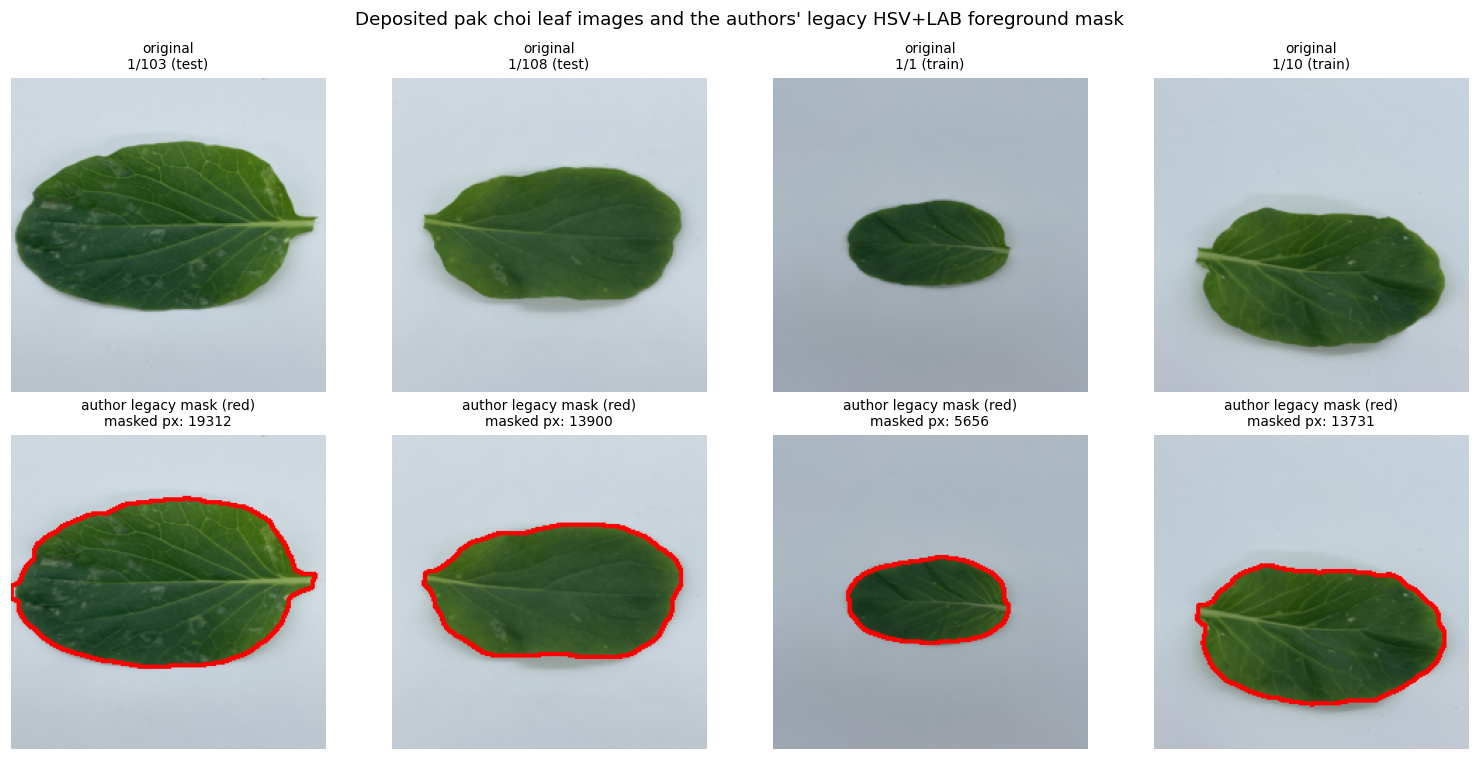

saved /content/input_preview.png


In [ ]:
import numpy as np, cv2, matplotlib.pyplot as plt
from PIL import Image
sample_rows = pd.concat([manifest[manifest.split == "test"].sort_values("sample_id").head(2),
                         manifest[manifest.split == "train"].sort_values("sample_id").head(2)])
def author_legacy_mask(rgb_bgr):
    blurred = cv2.GaussianBlur(rgb_bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    mask = cv2.bitwise_and(cv2.inRange(hsv, np.array([25, 40, 40]), np.array([85, 255, 255])),
                           (lab[:, :, 1] < 127).astype(np.uint8) * 255)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        max_c = max(cnts, key=cv2.contourArea)
        filled = np.zeros_like(mask)
        cv2.drawContours(filled, [max_c], -1, 255, -1)
        mask = filled
    return mask
fig, axes = plt.subplots(2, 4, figsize=(14, 7), dpi=110)
for col, (_, row) in enumerate(sample_rows.iterrows()):
    bgr = cv2.cvtColor(np.array(Image.open(PROJ/row.image_path).convert("RGB")), cv2.COLOR_RGB2BGR)
    mask = author_legacy_mask(bgr)
    overlay = bgr.copy()
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(overlay, cnts, -1, (0, 0, 255), 2)
    axes[0, col].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"original\n{row.sample_id} ({row.split})", fontsize=9)
    axes[1, col].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"author legacy mask (red)\nmasked px: {(mask>0).sum()}", fontsize=9)
    for ax in (axes[0, col], axes[1, col]): ax.axis("off")
fig.suptitle("Deposited pak choi leaf images and the authors' legacy HSV+LAB foreground mask", fontsize=12)
plt.tight_layout(); plt.savefig("/content/input_preview.png", bbox_inches="tight"); plt.show()
print("saved /content/input_preview.png")

## 8. Label overview — six pigment-related traits

The manifest carries the reference measurements for the six traits (`chl_a`, `chl_b`, `total_chl`,
`carot`, `total_carot`, `SPAD`) with the fixed 691/173 train/test split (group-disjoint plants).
Units: the authors' code records the label unit as *"source label unit (mg/g in legacy plots;
unverified)"* (`revision/common.py`, `save_predictions`) and the legacy script axes label chlorophyll
a as mg·g⁻¹; SPAD is a SPAD-index value. Per the deposit README, Group 1 `total_carot` labels were
corrected on 2026-11-16; as shown in section 6, the deposit's `test_metrics.csv` is consistent with
these corrected labels, while the prediction-table `y_true` column for that trait is stale.
*(Japanese) 6形質の参照測定値の範囲を示します。単位は著者コードの記載に従い、total_carotは
ラベル修正の注意書きがあります。*

In [ ]:
traits = ["chl_a", "chl_b", "total_chl", "carot", "total_carot", "SPAD"]
lab = manifest.copy()
lab[traits] = lab[traits].astype(float)
summary = lab.groupby("split")[traits].agg(["count", "min", "median", "max"]).round(3)
summary.columns = ["_".join(c) for c in summary.columns]
print("fixed split:", lab.split.value_counts().to_dict(),
      "| distinct groups per split:", lab.groupby("split").group_id.nunique().to_dict())
display(summary.T)

fixed split: {'train': 691, 'test': 173} | distinct groups per split: {'test': 173, 'train': 691}


split,test,train
chl_a_count,173.000,691.000
chl_a_min,2.272,1.641
chl_a_median,4.905,5.015
chl_a_max,13.872,13.872
chl_b_count,173.000,691.000
chl_b_min,0.316,0.299
chl_b_median,1.444,1.449
chl_b_max,10.978,13.312
total_chl_count,173.000,691.000
total_chl_min,2.776,1.507


## 9. Author feature extraction (compact128)

Run the authors' `revision.features.ensure_features` exactly as their pipeline does: the frozen
config's `feature_schema=compact128` selects the authors' 128-dim extractor (72 colour + 12 edge +
10 LBP + 10 shape + 20 GLCM + 4 gray-statistics features, derived in `revision/compact_features.py`
from the legacy 394-dim function in `code/ML/ML_chla.py` with unchanged segmentation). The author
code also re-verifies every image SHA-256 before extraction. Expected: `X` of shape (864, 128) in
well under a minute.
*(Japanese) 著者コードの特徴量抽出（128次元）をそのまま実行します。全画像のSHA-256も
著者コード内で再検証されます。*

In [ ]:
import subprocess, sys, os, time, numpy as np
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "revision.features", "--run", RUN],
                   cwd="/content/project", capture_output=True, text=True, timeout=1800)
print("rc:", r.returncode, "| elapsed: %.1fs" % (time.time() - t0))
print(r.stdout[-500:]); print(r.stderr[-500:])
if r.returncode != 0: raise RuntimeError("author feature extraction failed")
arr = np.load(PROJ/"revision"/"runs"/RUN/"features.npz", allow_pickle=False)
X_features = arr["X"]
print("feature matrix shape:", X_features.shape, "| finite rows:", int(np.isfinite(X_features).all(axis=1).sum()), "/", X_features.shape[0])

rc: 0 | elapsed: 13.1s
 / 864
Feature extraction 450 / 864
Feature extraction 475 / 864
Feature extraction 500 / 864
Feature extraction 525 / 864
Feature extraction 550 / 864
Feature extraction 575 / 864
Feature extraction 600 / 864
Feature extraction 625 / 864
Feature extraction 650 / 864
Feature extraction 675 / 864
Feature extraction 700 / 864
Feature extraction 725 / 864
Feature extraction 750 / 864
Feature extraction 775 / 864
Feature extraction 800 / 864
Feature extraction 825 / 864
Feature extraction 850 / 864


feature matrix shape: (864, 128) | finite rows: 864 / 864


## 10. Traditional-ML re-run for chlorophyll a (author pipeline, full grid)

Run the authors' pinned `revision.ml_pipeline` for trait `chl_a` under the frozen run configuration:
per model a scikit-learn `Pipeline` (median imputer → RobustScaler → SelectKBest with
mutual-information ranking, k=128) inside `GridSearchCV` over the authors' `balanced128` profile
grids, with the five fixed training `cv_fold` splits (group-disjoint) and scoring R²/RMSE/MAE, then
a single refit and predictions for all 864 entries. This is the authors' code, unmodified; on the
2-vCPU CPU runtime the full grid (about 515 fits) takes roughly 10–20 minutes — this is the longest
cell of the notebook.
*(Japanese) 著者のMLパイプラインをクロロフィルaについて凍結設定のまま（グリッド探索込み）実行します。
CPUランタイムで約10〜20分かかる最大のセルです。*

In [ ]:
import subprocess, sys, os, time
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "revision.ml_pipeline", "--run", RUN, "--trait", "chl_a"],
                   cwd="/content/project", capture_output=True, text=True, timeout=5400,
                   env={**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1",
                        "MKL_NUM_THREADS": "1", "NUMEXPR_NUM_THREADS": "1", "MPLBACKEND": "Agg"})
elapsed_rerun = time.time() - t0
print("rc:", r.returncode, "| elapsed: %.1f min" % (elapsed_rerun / 60))
print(r.stdout[-4000:]); print(r.stderr[-1500:])
if r.returncode != 0: raise RuntimeError("author ML pipeline failed")

rc: 0 | elapsed: 6.6 min
ML START chl_a PLS
ML COMPLETE chl_a PLS test {'n': 173, 'R2': 0.31276141547270453, 'RMSE': 1.6246900453273212, 'MAE': 1.2565252828368685}
ML START chl_a SVR
ML COMPLETE chl_a SVR test {'n': 173, 'R2': 0.8570436303088578, 'RMSE': 0.7410005112833392, 'MAE': 0.3694966999813761}
ML START chl_a Random_Forest
ML COMPLETE chl_a Random_Forest test {'n': 173, 'R2': 0.8389083667732995, 'RMSE': 0.7865987365185236, 'MAE': 0.5162379847713333}
ML START chl_a XGBoost
ML COMPLETE chl_a XGBoost test {'n': 173, 'R2': 0.773143925663612, 'RMSE': 0.9334519309335441, 'MAE': 0.6410575258881145}
ML START chl_a KNN
ML COMPLETE chl_a KNN test {'n': 173, 'R2': 0.7772457049454348, 'RMSE': 0.9249745753436129, 'MAE': 0.3401519546242775}




## 11. Re-run vs archived test metrics (chlorophyll a) and prediction scatter

Load the re-run's completed-model records (`ML/chla/revised/<run>/<model>_completed.json`, written by
the author code) and compare their fixed-test-set metrics with the archived ones recomputed in
section 6. Library-version differences (scikit-learn 1.6.1 / xgboost 2.1.4 vs the authors'
1.3.2 / 2.0.3, plus numpy 2.x) can shift tree-based and SVR results; the table reports both. The
scatter shows the re-run test predictions of the best re-run model against the measured values with
a 1:1 line — a notebook-generated visualization, not an author figure.
*(Japanese) 再実行結果とアーカイブ済みテスト指標を比較します。ライブラリバージョンの差により
乖離が出る可能性があるため、両方を表で示します。散布図はこのノートブックで作成した追加図です。*

,model,rerun_test_R2,rerun_test_RMSE,rerun_test_MAE,rerun_cv_R2_mean,rerun_best_params,archived_R2,archived_RMSE,archived_MAE
0,PLS,0.3128,1.6247,1.2565,0.2442,"{""feature_selection__k"": 128, ""model__n_compon...",0.3128,1.6247,1.2565
1,SVR,0.8570,0.7410,0.3695,0.7437,"{""feature_selection__k"": 128, ""model__C"": 10.0...",0.8570,0.7410,0.3695
2,Random_Forest,0.8389,0.7866,0.5162,0.7232,"{""feature_selection__k"": 128, ""model__max_dept...",0.8390,0.7865,0.5162
3,XGBoost,0.7731,0.9335,0.6411,0.7194,"{""feature_selection__k"": 128, ""model__learning...",0.7731,0.9335,0.6411
4,KNN,0.7772,0.9250,0.3402,0.5563,"{""feature_selection__k"": 128, ""model__n_neighb...",0.7772,0.9250,0.3402


best re-run model by test R2: SVR (R2=0.8570)


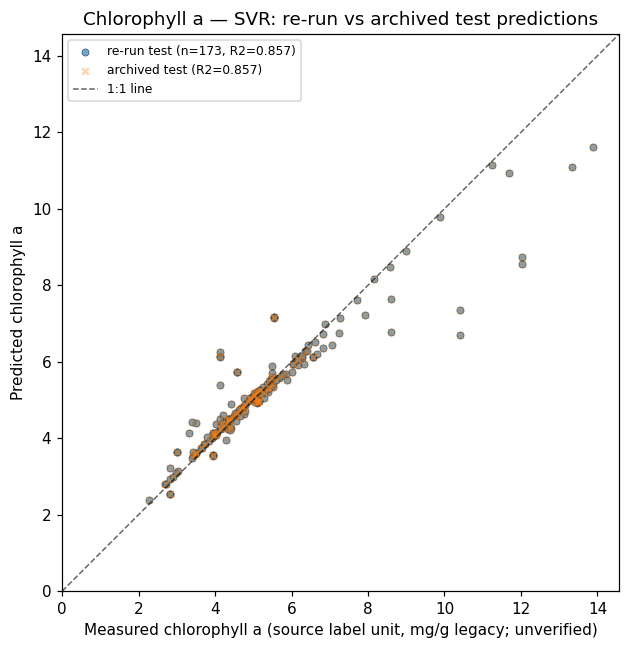

saved /content/chla_scatter.png


In [ ]:
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
models = ["PLS", "SVR", "Random_Forest", "XGBoost", "KNN"]
rerun_out = PROJ/"ML"/"chla"/"revised"/RUN
rows = []
for name in models:
    meta = json.load(open(rerun_out/f"{name}_completed.json"))
    te, cv = meta["metrics"]["test"], meta["cv"]["R2"]
    rows.append({"model": name, "rerun_test_R2": te["R2"], "rerun_test_RMSE": te["RMSE"], "rerun_test_MAE": te["MAE"],
                 "rerun_cv_R2_mean": cv["mean"], "rerun_best_params": json.dumps(meta["best_params"])})
rerun = pd.DataFrame(rows)
archived_chl = archived[archived.trait == "chl_a"][["model", "R2", "RMSE", "MAE"]].rename(
    columns={"R2": "archived_R2", "RMSE": "archived_RMSE", "MAE": "archived_MAE"})
comparison = rerun.merge(archived_chl, on="model").round(4)
display(comparison)
best = comparison.loc[comparison.rerun_test_R2.idxmax()]
print(f"best re-run model by test R2: {best.model} (R2={best.rerun_test_R2:.4f})")
preds_all = pd.read_csv(PROJ/"results/core_models/all_predictions.csv")
arch_sc = preds_all[(preds_all.trait == "chl_a") & (preds_all.split == "test") & (preds_all.model == best.model)]
rerun_sc = pd.read_csv(rerun_out/f"{best.model}_predictions.csv")
rerun_sc = rerun_sc[rerun_sc.split == "test"]
fig, ax = plt.subplots(figsize=(6.4, 6.0), dpi=110)
ax.scatter(rerun_sc.y_true, rerun_sc.y_pred, s=22, alpha=0.65, edgecolors="k", linewidths=0.4,
           label=f"re-run test (n={len(rerun_sc)}, R2={best.rerun_test_R2:.3f})")
ax.scatter(arch_sc.y_true, arch_sc.y_pred, s=18, alpha=0.35, marker="x",
           label=f"archived test (R2={best.archived_R2:.3f})")
lim = max(rerun_sc.y_true.max(), rerun_sc.y_pred.max(), arch_sc.y_true.max(), arch_sc.y_pred.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.6, label="1:1 line")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Measured chlorophyll a (source label unit, mg/g legacy; unverified)")
ax.set_ylabel("Predicted chlorophyll a")
ax.set_title(f"Chlorophyll a — {best.model}: re-run vs archived test predictions")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("/content/chla_scatter.png", bbox_inches="tight"); plt.show()
print("saved /content/chla_scatter.png")

## 12. Export the comparison table

Save the comparison table as CSV inside the Colab VM (`/content/chla_comparison.csv`) and show the
recorded provenance of this run. The learner can download it via the Colab file browser.
*(Japanese) 比較表をCSVとして保存します（Colabのファイルブラウザからダウンロードできます）。*

In [ ]:
comparison.to_csv("/content/chla_comparison.csv", index=False)
print("saved /content/chla_comparison.csv")
print("provenance: repository", "luoj49061-glitch/PakChoi-Pigment-Prediction @", PINNED,
      "| archived run_id:", preds_all.run_id.unique().tolist(),
      "| numpy", md.version("numpy"), "| scikit-learn", md.version("scikit-learn"),
      "| xgboost", md.version("xgboost"), "| opencv", md.version("opencv-python-headless"))

saved /content/chla_comparison.csv
provenance: repository luoj49061-glitch/PakChoi-Pigment-Prediction @ 2e54f5072128512e77a308efbe5fe341393f61bf | archived run_id: ['20260921_210614_balanced128'] | numpy 2.4.6 | scikit-learn 1.6.1 | xgboost 2.1.4 | opencv 4.10.0.84


## 13. Interpretation, limitations, references

**What this demonstrates.** The authors' deposited package reconstructs faithfully and its core
claims are self-consistent: all 864 deposited images match the manifest SHA-256, the fixed 173-sample
test split is group-disjoint, and the recomputed archived test metrics reproduce the deposit's
`test_metrics.csv` for all 36 trait×model groups. Re-running the authors' traditional-ML branch for
chlorophyll a under the frozen configuration and fixed splits reproduces the archived test metrics
(both tables are shown above); the one documented inconsistency is the stale `total_carot`
`y_true` column in the archived prediction table, which the deposit README itself flags.

**Limitations.**
- This is a one-trait, five-model partial demonstration on the deposited data — it does not verify
  the paper's dataset-level accuracy claims, the ResNet18 fusion results (no checkpoints in the
  deposit), the outer cross-validation, or the bootstrap comparisons.
- The authors' Python-3.8 environment pins could not be installed on Colab's Python 3.13; numpy/
  pandas/scikit-learn/scikit-image are current Colab versions and xgboost is 2.1.4 instead of 2.0.3
  (the authors' 2.0.3 is incompatible with scikit-learn 1.6). OpenCV matches the authors' pin.
  Any metric differences from the library versions are visible in the comparison table.
- The authors' `verify_deposit.py` cannot pass as-is because the archived `total_carot`
  prediction-table labels predate the documented correction (deposit README, 2026-11-16); sections
  5–6 report this precisely, and the archived metrics themselves agree with the corrected labels.
- Label units follow the authors' code note ("mg/g in legacy plots; unverified"); the imaging setup
  and reference assay details could not be verified because the publisher full text was inaccessible
  (methods beyond the abstract remain unverified from the paper side).
- The repository has no LICENSE file; content is used here for attribution-based reproduction and
  teaching only. The GitHub account's authorship is not ORCID-verified.

**References.** Paper DOI 10.1016/j.atech.2026.102781; author deposit commit
`2e54f5072128512e77a308efbe5fe341393f61bf` (fetched 2026-11-27): `verify_deposit.py`,
`code/revision/{common,features,compact_features,balancing,ml_pipeline}.py`, `code/ML/ML_chla.py`,
`supplementary/README.txt`, `supplementary/environment.json`, `results/core_models/`,
`data/sample_manifest.csv`. PhenoPaper investigation `p-6bfbd9d8cc2c3a07d17c29e6e80bf1fa-20261127T211330Z-1065416`
was used as prior research guidance, not as primary evidence.
*(Japanese) 上記の通り、本ノートブックは1形質・5モデルの部分再現です。論文レベルの精度検証、
ResNet18分岐、外部CV・ブートストラップは範囲外です。total_carotの予測表y_true列がラベル修正前の
値である点、ライブラリバージョン差の点、ライセンス未記載の点にご注意ください。*

In [ ]:
import time
print(f"notebook wall time: {(time.time() - t_notebook_start)/60:.1f} min")
print("DONE — pak choi pigment prediction: deposit audit + chl_a traditional-ML re-run")

notebook wall time: 7.4 min
DONE — pak choi pigment prediction: deposit audit + chl_a traditional-ML re-run
